# 1. 准备数据
# 1.1 定义x和y

In [386]:
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
x = torch.randn(100, 1)
noise = torch.randn(100, 1) * 0.1
y = 2.5 * x + 5.2 + noise
print(y)

tensor([[ 2.7886],
        [ 4.5678],
        [10.3782],
        [ 2.7985],
        [ 8.3149],
        [ 5.5409],
        [ 3.3667],
        [ 2.5577],
        [ 5.5863],
        [ 6.5033],
        [ 2.1635],
        [ 5.4575],
        [ 9.2939],
        [ 4.8389],
        [ 4.0792],
        [ 1.2772],
        [ 9.0634],
        [ 4.6710],
        [ 5.7665],
        [ 2.3530],
        [ 1.4288],
        [ 4.7572],
        [ 5.9183],
        [ 7.2991],
        [ 1.8214],
        [ 4.5594],
        [ 6.0946],
        [ 3.6969],
        [ 6.8962],
        [ 1.1784],
        [ 6.2111],
        [ 8.3169],
        [ 2.3306],
        [ 6.9806],
        [ 3.6015],
        [ 6.3045],
        [ 5.8119],
        [ 3.6615],
        [ 4.9022],
        [ 7.1614],
        [ 4.4587],
        [ 0.0728],
        [ 6.6782],
        [ 6.4469],
        [ 0.0295],
        [ 1.2215],
        [ 3.4764],
        [-0.1464],
        [ 0.5046],
        [ 4.9552],
        [ 3.3260],
        [ 8.6577],
        [ 3.

# 1.2 构建数据集

In [387]:

dataset = TensorDataset(x, y)

# 1.3 定义数据加载器


In [388]:
dataloader = DataLoader(dataset, batch_size=10, shuffle=True)

# 2. 构建模型

In [389]:
model = nn.Linear(1, 1)

# 3. 定义损失函数和优化器

In [390]:
epochN=500
lr = 0.11##lr=0.001
loss_fn = nn.MSELoss()
optimizer = optim.SGD(model.parameters())

# 4. 模型训练

In [391]:
loss_list = []
# 循环训练多轮
for epoch in range(epochN):
    total_loss = 0
    # 每个轮次，遍历所有批次进行迭代
    for x_batch, y_batch in dataloader:
        # 4.1 前向传播，计算模型预测输出值
        y_pred = model(x_batch)
        # 4.2 计算损失
        loss = loss_fn(y_pred, y_batch)
        # 4.3 反向传播，计算梯度
        loss.backward()
        # 4.4 更新参数
        optimizer.step()
        # 4.5 梯度清零
        optimizer.zero_grad()
        # 累加损失
        total_loss += loss.item()
    # 将本轮平均损失添加到列表
    loss_list.append( total_loss / len(dataloader) )

print("训练完成时的模型参数：")
print(model.weight) #W2.5
print(model.bias) #B 5.2

训练完成时的模型参数：
Parameter containing:
tensor([[2.4990]], requires_grad=True)
Parameter containing:
tensor([5.2026], requires_grad=True)


# 查看数据

In [392]:
print(loss_list)

[29.05348720550537, 27.99692268371582, 26.97264289855957, 25.991731262207033, 25.040076446533202, 24.12884864807129, 23.253029918670656, 22.40626726150513, 21.58966770172119, 20.809015941619872, 20.049365425109862, 19.32684507369995, 18.623108386993408, 17.94893035888672, 17.29571475982666, 16.674788188934325, 16.068293190002443, 15.4853196144104, 14.92739372253418, 14.389098644256592, 13.866967296600341, 13.370502614974976, 12.886402702331543, 12.422623348236083, 11.974630355834961, 11.5433424949646, 11.127433395385742, 10.72689847946167, 10.342544412612915, 9.97013192176819, 9.612291479110718, 9.268340635299683, 8.935481357574464, 8.616782426834106, 8.307960152626038, 8.009757280349731, 7.723710203170777, 7.446503591537476, 7.180577898025513, 6.924223804473877, 6.677752590179443, 6.438990759849548, 6.209446763992309, 5.988373494148254, 5.775354862213135, 5.569987320899964, 5.3721623659133915, 5.18083131313324, 4.996027684211731, 4.818333911895752, 4.648050832748413, 4.482435202598571

In [393]:
print(y_pred.detach().squeeze(dim=1))

tensor([8.9721, 5.6674, 6.0991, 2.4558, 2.6126, 7.3737, 3.4955, 4.4284, 1.2565,
        7.5826])


# 画图

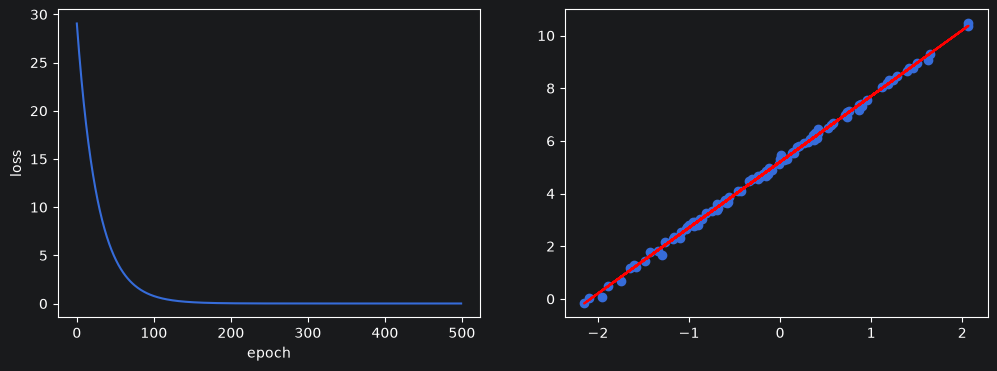

In [394]:

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# 1. 训练误差随轮次下降曲线
## 按数据索引位置自动添充x轴
ax[0].plot(loss_list)
## x轴代表位置
ax[0].set_xlabel('epoch')
## y轴代表损失
ax[0].set_ylabel('loss')
# 2. 散点图
ax[1].scatter(x, y)
y_pred = model(x)
y_pred = y_pred.detach().squeeze()
#拟合直线
ax[1].plot(x, y_pred, color='red')
plt.show()

## 总结
## 调超参数
### 学习率
默认是0.001 太小会比较慢，太大容易发散

### epoch 轮次
epoch 也要配合学习率适当调整 太大浪费资源 太小模型损失过大 不够好